<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Fig2_Reproduce_2024_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reproduce IEEE Manuscript Figure 2

**Purpose:** Recreate Fig. 2 using the 24-hour measurements and optimizer decisions already saved by `PGCB_IEEE_Final_Validation_2024_Colab.ipynb`.

**Data provenance:** `final_hourly_schedules_2024.csv` was generated by the 2024 validation code. Fig. 2 itself was initially plotted separately during manuscript editing; it was not saved by that original Colab notebook. This small notebook closes the gap by saving the plot to **your Google Drive**.

The figure compares the actual hourly PGCB demand for **January 1, 2024** with *counterfactual* UAD-WF Q90 and independently optimized robust MILP schedules at **15% assumed load flexibility**. No new algorithm training or tuning occurs.

The figure will be saved at **600 DPI (PNG)** and as a **vector PDF**, accompanied by an auditable 24-hour CSV and source checksum.

## 1. Locate the original 2024 hourly simulation CSV in your Google Drive

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4

# Connect Google Drive; the original 2024 validation notebook has already
# saved the hourly simulation CSV there.
from google.colab import drive
drive.mount('/content/drive')

PROJECT = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
RUNS = PROJECT / 'runs'
RUN_ID = 'ieee_final_2024_20261108T042536Z_4eecbb'  # recorded in your protocol JSON

# Prefer the exact experiment you shared; fall back to another completed
# 2024 run only if that run is not present in your Drive.
preferred = RUNS / RUN_ID / 'final_hourly_schedules_2024.csv'
if preferred.exists():
    CSV_PATH = preferred
else:
    candidates = sorted(RUNS.glob('ieee_final_2024_*/final_hourly_schedules_2024.csv'))
    if not candidates:
        raise FileNotFoundError(
            'Cannot find final_hourly_schedules_2024.csv in Google Drive. '
            'Please ensure your 2024 validation run completed and saved its hourly CSV '
            'under MyDrive/PGCB_Demand_Optimization/runs/ieee_final_2024_*/.'
        )
    CSV_PATH = candidates[-1]
    print('Note: preferred run not found; using:', CSV_PATH.parent.name)

DEST = RUNS / ('fig2_reproduced_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
               + '_' + uuid4().hex[:6])
DEST.mkdir(parents=True, exist_ok=False)
print('Reading original hourly results:', CSV_PATH)
print('Saving figure and audit data to:', DEST)

Mounted at /content/drive
Reading original hourly results: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/ieee_final_2024_20261108T042536Z_4eecbb/final_hourly_schedules_2024.csv
Saving figure and audit data to: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/fig2_reproduced_20261108T062924Z_6fc418


## 2. Verify the 24-hour schedules and generate Fig. 2

The code confirms that each method contains 24 hours, uses the same observed demand, and conserves total daily energy. The observed PGCB demand and the simulated schedules are clearly distinguished.

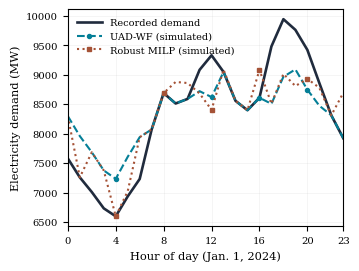

PNG pixel size: (2063, 1540) | DPI metadata: (599.9988, 599.9988)
Original daily peak: 9944.00 MW
NoAction: peak 9944.00 MW, reduction 0.000%
WaterfillQ90: peak 9091.42 MW, reduction 8.574%
UnrestrictedExactRobustMILPQ90: peak 9088.07 MW, reduction 8.608%
Saved 600-DPI PNG: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/fig2_reproduced_20261108T062924Z_6fc418/Fig2_Daily_Demand_2024_600dpi.png
Saved vector PDF: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/fig2_reproduced_20261108T062924Z_6fc418/Fig2_Daily_Demand_2024_Vector.pdf
Saved exact source rows: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/fig2_reproduced_20261108T062924Z_6fc418/Fig2_24Hour_Source_Rows.csv
Saved reproducibility record: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/fig2_reproduced_20261108T062924Z_6fc418/Fig2_Provenance.json


In [ ]:
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATE = '2024-01-01'              # first eligible day, not selected for best performance
ALPHA = 0.15                    # hypothetical 15% hourly demand flexibility
METHODS = [
    'NoAction',
    'WaterfillQ90',
    'UnrestrictedExactRobustMILPQ90',
]

# Load the Colab-generated hourly results: do NOT make up or smooth values.
cols = ['date', 'hour', 'alpha', 'method', 'actual_mw', 'shift_mw', 'simulated_mw',
        'violates_assumed_actual_cap']
df = pd.read_csv(CSV_PATH, usecols=cols)
sub = df.loc[(df['date'] == DATE) & np.isclose(df['alpha'], ALPHA)
             & df['method'].isin(METHODS)].copy()

series = {}
for name in METHODS:
    rows = sub.loc[sub['method'] == name].sort_values('hour').copy()
    if len(rows) != 24 or not np.array_equal(rows['hour'].to_numpy(), np.arange(24)):
        raise ValueError(f'Expected exactly 24 hourly rows for {name} on {DATE}; got {len(rows)}')
    if not np.allclose(rows['actual_mw'] + rows['shift_mw'], rows['simulated_mw'], atol=1e-6):
        raise ValueError(f'Simulated demand does not equal actual demand + shift for {name}')
    if not np.isclose(rows['shift_mw'].sum(), 0, atol=1e-5):
        raise ValueError(f'Energy is not conserved for {name}')
    if int(rows['violates_assumed_actual_cap'].sum()):
        print('WARNING: retrospective cap violation exists for:', name)
    series[name] = rows

baseline = series['NoAction']['actual_mw'].to_numpy()
for name in METHODS[1:]:
    if not np.allclose(series[name]['actual_mw'].to_numpy(), baseline):
        raise ValueError('Methods do not have identical observed demand inputs')

# Professional IEEE single-column plot with the same navy/teal/brown style
# used in the manuscript; no model results or data values are changed.
plt.rcParams.update({'font.family': 'DejaVu Serif', 'pdf.fonttype': 42,
                     'axes.linewidth': 0.8, 'savefig.facecolor': 'white'})
fig, ax = plt.subplots(figsize=(3.48, 2.60))
h = np.arange(24)
ax.plot(h, baseline, color='#202b3d', lw=1.9, label='Recorded demand')
ax.plot(h, series['WaterfillQ90']['simulated_mw'].to_numpy(),
        color='#057f97', lw=1.5, ls='--', marker='o', markevery=[4, 8, 12, 16, 20],
        ms=2.9, label='UAD-WF (simulated)')
ax.plot(h, series['UnrestrictedExactRobustMILPQ90']['simulated_mw'].to_numpy(),
        color='#a55236', lw=1.5, ls=':', marker='s', markevery=[4, 8, 12, 16, 20],
        ms=2.9, label='Robust MILP (simulated)')
ax.set_xlabel('Hour of day (Jan. 1, 2024)', fontsize=8.2)
ax.set_ylabel('Electricity demand (MW)', fontsize=8.2)
ax.set_xticks([0, 4, 8, 12, 16, 20, 23])
ax.set_xlim(0, 23)
ax.grid(alpha=0.18, linewidth=0.5)
ax.tick_params(labelsize=7.2)
ax.legend(loc='upper left', fontsize=7.0, frameon=False, handlelength=2.6)
fig.tight_layout(pad=0.3)

png = DEST / 'Fig2_Daily_Demand_2024_600dpi.png'
pdf = DEST / 'Fig2_Daily_Demand_2024_Vector.pdf'
fig.savefig(png, dpi=600, bbox_inches='tight', pad_inches=0.02)
fig.savefig(pdf, bbox_inches='tight', pad_inches=0.02)
plt.show()
plt.close(fig)

selected_data = DEST / 'Fig2_24Hour_Source_Rows.csv'
sub.sort_values(['method', 'hour']).to_csv(selected_data, index=False)

stats = {}
peak0 = float(np.max(baseline))
for name in METHODS:
    r = series[name]
    peak = float(r['simulated_mw'].max())
    stats[name] = {
        'peak_mw': peak,
        'peak_reduction_pct': 100.0*(peak0-peak)/peak0,
        'shifted_mwh': float(np.abs(r['shift_mw']).sum()/2.0),
        'retrospective_cap_violating_hours': int(r['violates_assumed_actual_cap'].sum()),
    }
metadata = {
    'source_csv': str(CSV_PATH),
    'source_csv_sha256': hashlib.sha256(CSV_PATH.read_bytes()).hexdigest(),
    'selected_date': DATE,
    'assumed_flexibility': ALPHA,
    'methods': METHODS,
    'hourly_observations_per_method': 24,
    'meanings': {
        'actual_mw': 'PGCB recorded demand',
        'simulated_mw': 'counterfactual actual_mw + optimizer shift_mw',
    },
    'peak_metrics': stats,
    'png_dpi_requested': 600,
    'figure_type': 'retrospective counterfactual simulation; NOT physically implemented',
}
(DEST / 'Fig2_Provenance.json').write_text(json.dumps(metadata, indent=2))
with Image.open(png) as image:
    print('PNG pixel size:', image.size, '| DPI metadata:', image.info.get('dpi'))
print('Original daily peak: %.2f MW' % peak0)
for name in METHODS:
    print('%s: peak %.2f MW, reduction %.3f%%' %
          (name, stats[name]['peak_mw'], stats[name]['peak_reduction_pct']))
print('Saved 600-DPI PNG:', png)
print('Saved vector PDF:', pdf)
print('Saved exact source rows:', selected_data)
print('Saved reproducibility record:', DEST / 'Fig2_Provenance.json')

## Suggested manuscript caption

**Fig. 2.** Recorded hourly PGCB electricity demand and counterfactual demand profiles obtained using UAD-WF Q90 and independent robust MILP on January 1, 2024, under 15% assumed demand flexibility.

**Interpretation:** This fixed-date example illustrates the temporal redistribution of demand; it is not selected as the algorithm’s best-performing day and does not represent physical load shifting on the grid. The aggregate comparative findings should be taken from the separate 300-day evaluation table, not inferred from this single day.

**After execution:** The output path is printed by the notebook. Keep the PNG, PDF, 24-hour CSV, and provenance JSON together under `MyDrive/PGCB_Demand_Optimization/runs/fig2_reproduced_*`.